## 1. Setup ##

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from opa import array_intensity, fwhm, find_peaks

wl = 1.55e-6
d = wl / 2
theta = np.radians(np.linspace(-90, 90, 36001))   # 0.005° steps

## 2. Beamwidth against N ##

N =    8:  measured 12.803°   theory 12.691°
N =   16:  measured  6.359°   theory  6.346°
N =   32:  measured  3.174°   theory  3.173°
N =   64:  measured  1.586°   theory  1.586°
N =  128:  measured  0.793°   theory  0.793°
N =  256:  measured  0.397°   theory  0.397°


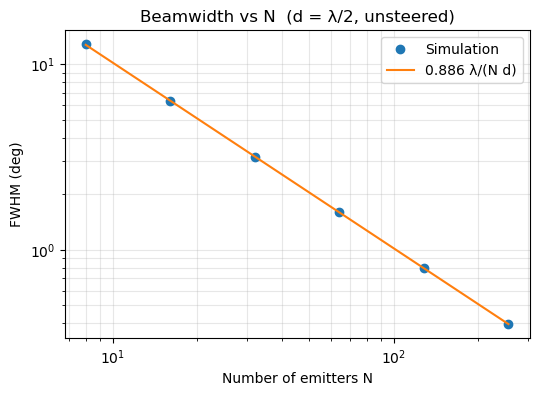

In [2]:
Ns = np.array([8, 16, 32, 64, 128, 256])
measured = [fwhm(theta, array_intensity(theta, n, d, wl, 0)) for n in Ns]
theory = np.degrees(0.886 * wl / (Ns * d))

for n, m, t in zip(Ns, measured, theory):
    print(f"N = {n:4d}:  measured {m:6.3f}°   theory {t:6.3f}°")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, measured, "o", label="Simulation")
ax.loglog(Ns, theory, "-", label="0.886 λ/(N d)")
ax.set_xlabel("Number of emitters N"); ax.set_ylabel("FWHM (deg)")
ax.set_title("Beamwidth vs N  (d = λ/2, unsteered)")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

## 3. Beamwidth against steering angle ##

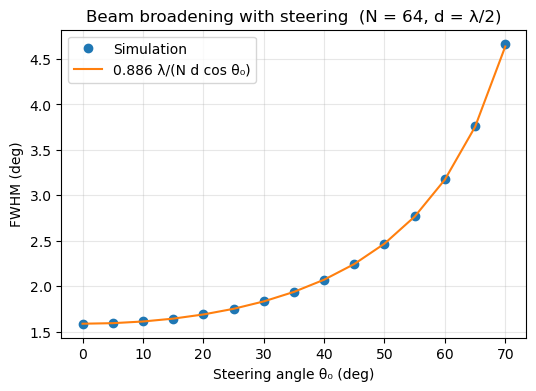

In [3]:
N = 64
steer = np.arange(0, 75, 5)
measured = []
for s in steer:
    dphi = 2 * np.pi * d / wl * np.sin(np.radians(s))
    measured.append(fwhm(theta, array_intensity(theta, N, d, wl, dphi)))
theory = np.degrees(0.886 * wl / (N * d * np.cos(np.radians(steer))))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(steer, measured, "o", label="Simulation")
ax.plot(steer, theory, "-", label="0.886 λ/(N d cos θ₀)")
ax.set_xlabel("Steering angle θ₀ (deg)"); ax.set_ylabel("FWHM (deg)")
ax.set_title(f"Beam broadening with steering  (N = {N}, d = λ/2)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 4. Sidelobe level against N (quick check) ##

In [5]:
for n in Ns:
    I = array_intensity(theta, n, d, wl, 0)
    _, vals = find_peaks(theta, I)
    print(f"N = {n:4d}:  strongest sidelobe {10*np.log10(np.sort(vals)[-2]):.2f} dB")

N =    8:  strongest sidelobe -12.80 dB
N =   16:  strongest sidelobe -13.15 dB
N =   32:  strongest sidelobe -13.23 dB
N =   64:  strongest sidelobe -13.25 dB
N =  128:  strongest sidelobe -13.26 dB
N =  256:  strongest sidelobe -13.26 dB


**Notes:** More emitters make the beam narrower but don't lower the strongest sidelobe. 

## 5. The LIDAR design question ##

How many emitters do you need for a 0.1° beam at 1550 nm with λ/2 spacing?

In [6]:
target = np.radians(0.1) # Small angle approximation
N_needed = 0.886 * wl / (d * target)
print(f"Emitters needed: {N_needed:.0f}")
print(f"Array width: {N_needed * d * 1e3:.2f} mm")
print(f"Spot size at 100 m: {100 * target * 100:.0f} cm")

Emitters needed: 1015
Array width: 0.79 mm
Spot size at 100 m: 17 cm


**Notes:** Spot size of 17cm is fine enough to resolve a pedestrian at 100m. But it needs about 1,000 independently controlled phase shifters, which is why power and control electronics are a major challenge for real LIDAR chips

**Questions:**
    
1. What does the slope of the log-log plot tell you, and why does it make physical sense? (Use the pairing argument.)
2. Why does the beam broaden with steering angle, and by how much at 60°?
3. Why doesn’t adding emitters lower the strongest sidelobe?
4. What’s the engineering cost of a 0.1° beam, and what does it mean for a real LIDAR?

## Efficiency ## 

d = 0.5λ: [0.908 0.904 0.903 0.903 0.903 0.903]
d = 2.0λ: [0.227 0.226 0.226 0.226 0.226 0.226]


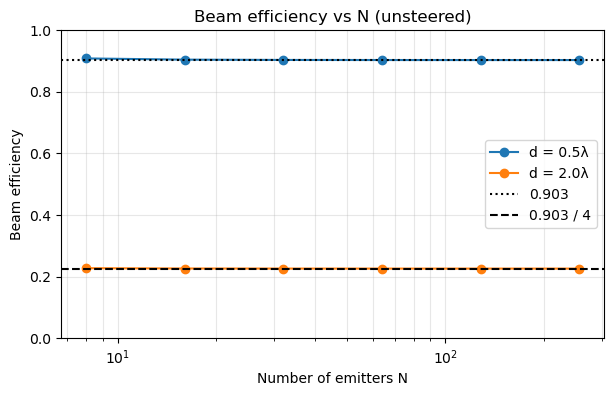

In [3]:
import importlib, opa; importlib.reload(opa)
from opa import power_budget

Ns_e = [8, 16, 32, 64, 128, 256]
fig, ax = plt.subplots(figsize=(7, 4))
for r in [0.5, 2.0]:
    eff = [power_budget(np.arange(n) * r * wl, wl, 0)["beam_eff"] for n in Ns_e]
    ax.semilogx(Ns_e, eff, "o-", label=f"d = {r}λ")
    print(f"d = {r}λ:", np.round(eff, 3))
ax.axhline(0.903, color="k", ls=":", label="0.903")
ax.axhline(0.903 / 4, color="k", ls="--", label="0.903 / 4")
ax.set_xlabel("Number of emitters N"); ax.set_ylabel("Beam efficiency"); ax.set_ylim(0, 1)
ax.set_title("Beam efficiency vs N (unsteered)"); ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

**Why its flat:** adding emitters makes the main lobe and its sidelobes narrower together. The pattern shrinks in angle but keeps the same sinc² shape, and a sinc² always has about 90% of its area in its main lobe. At d = 2λ, the light is still split between 4 beams’ worth of lobes, whatever N is

**How concentrated is the light?**

d = 0.5λ: D = [  8.  16.  32.  64. 128. 256.]
d = 2.0λ: D = [  8.  16.  32.  64. 128. 256.]


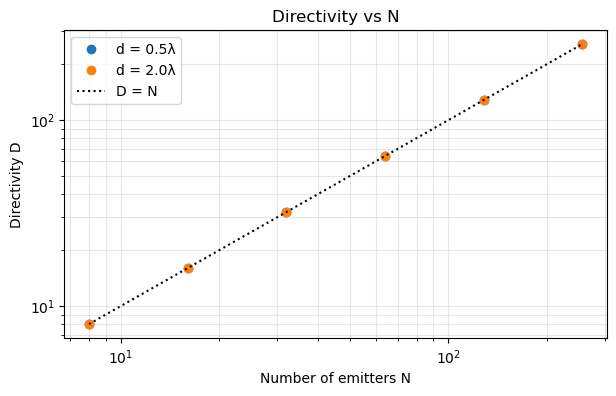

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for r in [0.5, 2.0]:
    D = [2 / power_budget(np.arange(n) * r * wl, wl, 0)["total"] for n in Ns_e]
    ax.loglog(Ns_e, D, "o", label=f"d = {r}λ")
    print(f"d = {r}λ: D =", np.round(D, 1))
ax.loglog(Ns_e, Ns_e, "k:", label="D = N")
ax.set_xlabel("Number of emitters N"); ax.set_ylabel("Directivity D")
ax.set_title("Directivity vs N"); ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

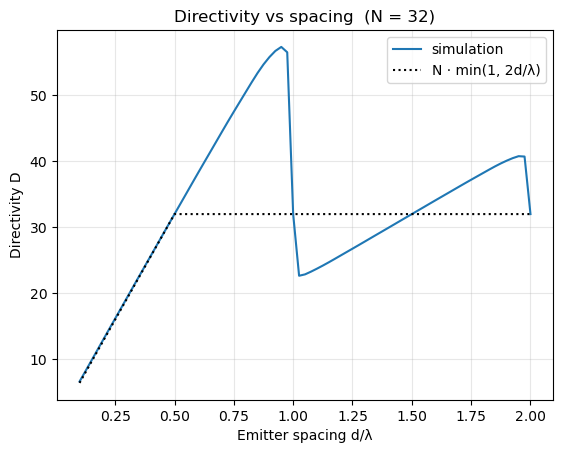

In [6]:
N_d = 32
r_sweep = np.linspace(0.1, 2.0, 77)
D = [2 / power_budget(np.arange(N_d) * r * wl, wl, 0)["total"] for r in r_sweep]
plt.plot(r_sweep, D, label="simulation")
plt.plot(r_sweep, N_d * np.minimum(1, 2 * r_sweep), "k:", label="N · min(1, 2d/λ)")
plt.xlabel("Emitter spacing d/λ"); plt.ylabel("Directivity D")
plt.title(f"Directivity vs spacing  (N = {N_d})"); plt.legend(); plt.grid(alpha=0.3); plt.show()

D rises with spacing up to d = λ/2, because a wider array gives a narrower beam. Above λ/2 it levels off at N, because grating lobes appear and the gain is shared. So λ/2 is the “sweet spot” spacing: maximum concentration of light without wasting any in grating lobes.

**What N means for a real target**

Beam efficiency doesn’t change with N, but how much light actually hits a small target does. Take a pedestrian about 0.5 m wide at 100 m range, which spans about 0.005 in sin θ:

In [7]:
trap = lambda y, x: np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x))
target_u = 0.5 / 100                                # 0.5 m wide at 100 m, in sin θ

for n in [16, 64, 256, 1024]:
    pb = power_budget(np.arange(n) * wl / 2, wl, 0)
    on_target = np.abs(pb["u"]) <= target_u / 2
    frac = trap(pb["I"] * on_target, pb["u"]) / pb["total"]
    fwhm_deg = np.degrees(0.886 * 2 / n)
    print(f"N = {n:5d}:  FWHM {fwhm_deg:5.2f}°,  spot at 100 m {100*np.radians(fwhm_deg):5.2f} m,  "
          f"light on a 0.5 m target: {frac:.0%}")

N =    16:  FWHM  6.35°,  spot at 100 m 11.08 m,  light on a 0.5 m target: 6%
N =    64:  FWHM  1.59°,  spot at 100 m  2.77 m,  light on a 0.5 m target: 18%
N =   256:  FWHM  0.40°,  spot at 100 m  0.69 m,  light on a 0.5 m target: 59%
N =  1024:  FWHM  0.10°,  spot at 100 m  0.17 m,  light on a 0.5 m target: 91%


**This is why N matters so much for LIDAR.** When the spot is much bigger than the target, most of the light goes past it. Bigger arrays squeeze the beam onto the target, until the beam is smaller than the target, at which point all of the main lobe hits it and you reach the 90% beam-efficiency ceiling.

**1. Beam efficiency doesn’t depend on N.** The pattern shrinks in angle but keeps its sinc² shape, so about 90% stays in the main lobe at λ/2, and about 23% at 2λ.

**2. Directivity grows as D = N.** Peak intensity grows as N² while total power grows as N. Wider spacing can’t beat this: narrower beams are cancelled out by the extra grating lobes. D peaks at N once d ≥ λ/2, so λ/2 is the ideal spacing

**3. For small or distant targets, N decides how much light hits them.** It rises from about 4% to about 90% for a 0.5 m target at 100 m as N goes from 16 to 1,024. That’s the real link between array size and LIDAR range for small objects.

**4. The overall picture so far:** spacing decides what fraction of the light is in the beam (Part 2), and N decides how tightly that light is concentrated (Part 3). A good LIDAR array needs both: λ/2 spacing (or an aperiodic workaround) and large N.